In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import pickle
import aux_functions as aux
import traceback
importlib.reload(aux)

def read_pkl(path):
    with open(path, "rb") as file:
        return pickle.load(file) 

def write_pkl(var, path):
    with open(path, "wb") as file:
        pickle.dump(var, file)

In [ ]:
start_time = -300
end_time = 300
bin_width = 50
step = 10
t_ends = np.arange(start_time + bin_width, end_time + step, step)

In [ ]:
import seaborn as sns
def plot_as_decoding(array, label='', chance_level=25):
    plt.figure(figsize=(10, 5))
    plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Chegada da Sacada (t=0)')
    plt.axhline(y=chance_level, color='black', linestyle=':', label=f"Chance Level ({chance_level:.1f}%)")
    plt.plot(t_ends, array, color='dodgerblue', linewidth=2.5, marker='o', label=label)
    plt.title(f'Decodificabilidade (1 Bin de 50ms)', fontsize=14)
    plt.ylabel('Acurácia (%)', fontsize=12)
    plt.ylim(0, 100)
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.show()

def plot_list_decoding(arrays, labels=[], chance_level=25):
    if labels == []: labels = ['']*len(arrays)
    plt.figure(figsize=(10, 5))
    plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Chegada da Sacada (t=0)')
    plt.axhline(y=chance_level, color='black', linestyle=':', label=f"Chance Level ({chance_level:.1f}%)")
    for i, array in enumerate(arrays):
        plt.plot(t_ends, array, linewidth=2.5, marker='o', label=labels[i])
    plt.title(f'Decodificabilidade (1 Bin de 50ms)', fontsize=14)
    plt.ylabel('Acurácia (%)', fontsize=12)
    plt.ylim(0, 100)
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


def plot_decoding_by_class(results, classes, titulo_plot='', txt_add_title='', chance_level=25):
    tempos = t_ends
    plt.figure(figsize=(10,6))
    for c in classes:
        acc_temporal = results[c]
        plt.plot(tempos, acc_temporal, marker='o', label=c)
    plt.axvline(x=0, color='red', linestyle='--', label='Chegada da Sacada')
    plt.axhline(y=chance_level, color='black', linestyle='--', label='Chance level')
    plt.ylabel('Acurácia (%)')
    plt.xlabel('Tempo em relação à fixação (ms)')
    plt.legend()
    plt.title(f'{titulo_plot}')
    plt.grid(True, alpha=0.3)
    plt.show()


In [ ]:
df_cell = read_pkl("session_data/all_sessions.pkl")
df_cell

,start,search,mapRF,grid_coord,depth,brain_area,sample,array,prefer,SI,RFin,RFout,coreRFin,,RF_type,session,neuron_id
0,1,m08cat186spk033a,m08det185spk033a,-1+6,1326,TE,0.0,0.0,face,0.486370,"0,8","1,2,3,4,5,6,7,9,10,11,12,13,14,15,16,17,18,19,20",0,NaN,Broad Foveal,m08cat186,spk033a
1,2,m08cat186spk033b,m08det185spk033b,-1+6,1326,TE,0.0,0.0,face,0.718640,"0,2","1,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20",0,NaN,Broad Foveal,m08cat186,spk033b
2,3,m08cat186spk033c,m08det185spk033c,-1+6,1326,TE,0.0,0.0,face,0.665560,"0,1,5,6,7,14,15,16,17","2,3,4,8,9,10,11,12,13,18,19,20","0,7,15",NaN,Broad Foveal,m08cat186,spk033c
3,6,m08cat186spk034a,m08det185spk034a,-1+6,1486,TE,0.0,NaN,house,-0.244390,NaN,NaN,NaN,NaN,Focal Foveal,m08cat186,spk034a
4,7,m08cat186spk034b,m08det185spk034b,-1+6,1486,TE,0.0,NaN,house,-0.185990,NaN,NaN,NaN,NaN,Focal Foveal,m08cat186,spk034b
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6171,3074,m06cat288spk126z,m06det287spk126z,+2-5,688,V4,0.0,NaN,NaN,0.073817,NaN,NaN,NaN,NaN,Focal Foveal,m06cat288,spk126z
6172,3077,m06cat288spk128a,m06det287spk128a,+2-5,698,V4,0.0,NaN,face,0.041171,NaN,NaN,NaN,NaN,Focal Foveal,m06cat288,spk128a
6173,3078,m06cat288spk128b,m06det287spk128b,+2-5,698,V4,0.0,NaN,NaN,0.103600,NaN,NaN,NaN,NaN,Focal Foveal,m06cat288,spk128b
6174,3079,m06cat288spk128c,m06det287spk128c,+2-5,698,V4,0.0,NaN,NaN,0.046372,NaN,NaN,NaN,NaN,Focal Foveal,m06cat288,spk128c


In [ ]:
dicio_acc_IT = {'all':{},'restrict':{}}
dicio_acc_V4 = {'all':{},'restrict':{}}

dicio_Nneurons_IT = {}
dicio_Nneurons_V4 = {}
dicio_Nselective_IT = {}
dicio_Nselective_V4 = {}


for i in range(33):
    print(i)
    dicio_save, list_errors = read_pkl(f'session_data/foveal_decoding_{i}.pkl')
    for session, data in dicio_save['IT'].items():
        dicio_acc_IT['all'][session] = data['decoding']#['mean_acc']
        dicio_acc_IT['restrict'][session] = data['decoding_restrict']#['mean_acc']
        dicio_Nneurons_IT[session] = len(data['dicio_firings'])
        # dicio_Nselective_IT[session] = len(df_cell[(df_cell['RF_type']=='Focal Foveal') & (df_cell['brain_area'].isin(['TE','TEO'])) & (df_cell['session']==session) & ~(df_cell['prefer'].isna())])
        dicio_Nselective_IT[session] = len(df_cell.query("RF_type == 'Focal Foveal' and brain_area in ['TE', 'TEO'] and session == @session and prefer.notna()"))
    for session, data in dicio_save['V4'].items():
        dicio_acc_V4['all'][session] = data['decoding']#['mean_acc']
        dicio_acc_V4['restrict'][session] = data['decoding_restrict']#['mean_acc']
        dicio_Nneurons_V4[session] = len(data['dicio_firings'])
        # dicio_Nselective_V4[session] = len(df_cell[(df_cell['RF_type']=='Focal Foveal') & (df_cell['brain_area']=='V4') & (df_cell['session']==session) & ~(df_cell['prefer'].isna())])
        dicio_Nselective_V4[session] = len(df_cell.query("RF_type == 'Focal Foveal' and brain_area == 'V4' and session == @session and prefer.notna()"))

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32


In [ ]:
# print(len(df_cell[(df_cell['session']=='m08cat135') & (df_cell['brain_area']=='V4')]))
# df_cell[(df_cell['session']=='m08cat135') & (df_cell['brain_area']=='V4')]
# print(dicio_Nneurons_V4['m08cat135'])

# ESSES MALDITOS DECODINGS SÃO USANDO TODOS NEURONIOS

In [ ]:
t_ends[40]

150

In [47]:
# ARR = np.max([value['mean_acc'] for value in dicio_acc_IT['all'].values()],axis=0)
# {t_ends[i]:ARR[i] for i in range(25,len(t_ends))}

In [ ]:
# np.sort([value['mean_acc'][40] for value in dicio_acc_V4['all'].values()])

array([24.3716696 , 24.72576073, 24.80146549, 24.86458931, 25.09069675,
       25.1916486 , 25.50883106, 25.55752076, 25.60021672, 25.72121389,
       25.91474091, 25.95971365, 25.99838932, 26.02329847, 26.11306189,
       26.18016485, 26.27357836, 26.38780168, 26.56554036, 26.62110395,
       26.64584678, 26.69502067, 26.72054695, 26.77395363, 26.82455595,
       26.88011244, 26.89757913, 26.97688648, 27.05503597, 27.06060406,
       27.08701586, 27.09328326, 27.20578155, 27.25626843, 27.30954882,
       27.31072956, 27.32094208, 27.34479162, 27.47981742, 27.79096806,
       27.82976959, 27.83414968, 27.87276813, 28.13557034, 28.43865528,
       28.44389828, 28.48038808, 28.48968483, 28.55601724, 28.64112878,
       28.83148028, 28.99395965, 29.09877061, 29.30056778, 29.51629055,
       29.85044727, 29.85936017, 29.88106317, 29.89390038, 30.19433412,
       30.22172482, 30.32995499, 30.85595982, 30.87306737, 31.21634947,
       31.35818562, 31.43621316, 31.7838993 , 31.91376521, 32.25

# análises iniciais

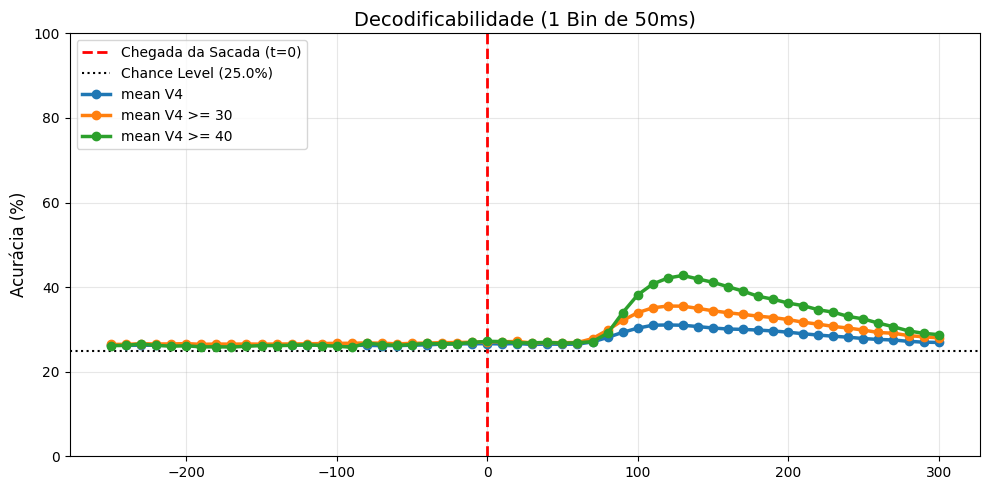

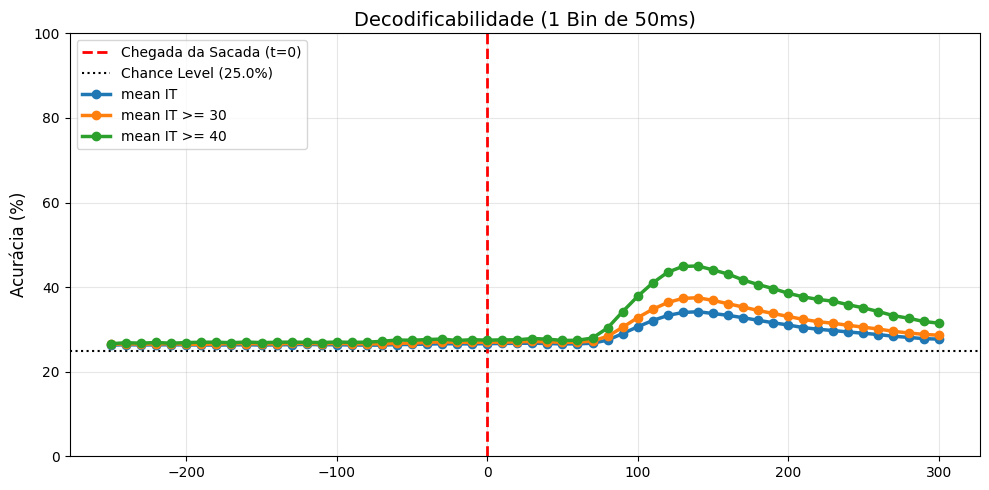

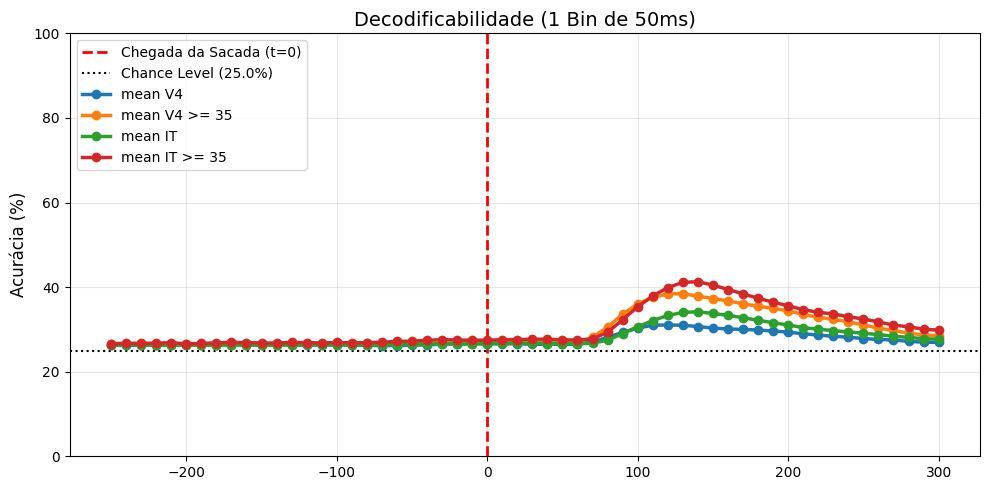

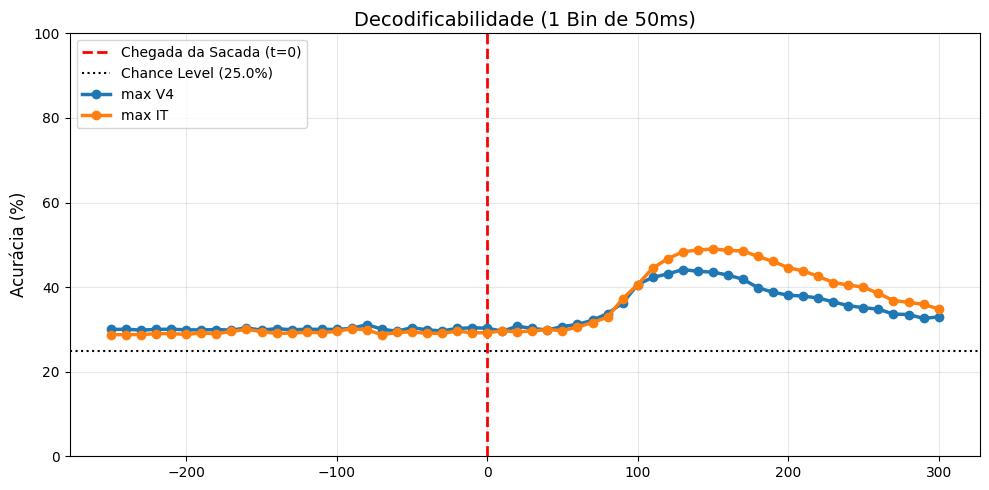

In [13]:
plot_list_decoding(
    [
        np.mean([value['mean_acc'] for value in dicio_acc_V4['all'].values()],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_V4['all'].values() if value['mean_acc'][37]>=30],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_V4['all'].values() if value['mean_acc'][37]>=40],axis=0),
    ],
    [
        'mean V4',
        'mean V4 >= 30',
        'mean V4 >= 40'
    ]
)


plot_list_decoding(
    [
        np.mean([value['mean_acc'] for value in dicio_acc_IT['all'].values()],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_IT['all'].values() if value['mean_acc'][37]>=30],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_IT['all'].values() if value['mean_acc'][37]>=40],axis=0),
    ],
    [
        'mean IT',
        'mean IT >= 30',
        'mean IT >= 40'
    ]
)

plot_list_decoding(
    [
        np.mean([value['mean_acc'] for value in dicio_acc_V4['all'].values()],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_V4['all'].values() if value['mean_acc'][37]>=35],axis=0),
        # np.mean([value['mean_acc'] for value in dicio_acc_V4['all'].values() if value['mean_acc'][37]>=40],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_IT['all'].values()],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_IT['all'].values() if value['mean_acc'][37]>=35],axis=0),
        # np.mean([value['mean_acc'] for value in dicio_acc_IT['all'].values() if value['mean_acc'][37]>=40],axis=0),
    ],
    [
        'mean V4',
        'mean V4 >= 35',
        # 'mean V4 >= 40',
        'mean IT',
        'mean IT >= 35',
        # 'mean IT >= 40'
    ]
)



plot_list_decoding(
    [
        np.max([value['mean_acc'] for value in dicio_acc_V4['all'].values()],axis=0),
        np.max([value['mean_acc'] for value in dicio_acc_IT['all'].values()],axis=0),
    ],
    [
        'max V4',
        'max IT',
    ]
)

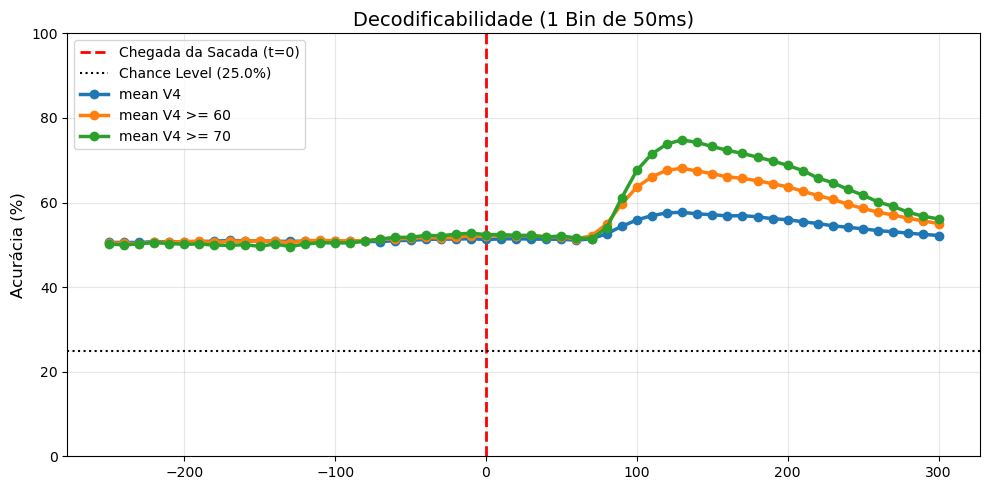

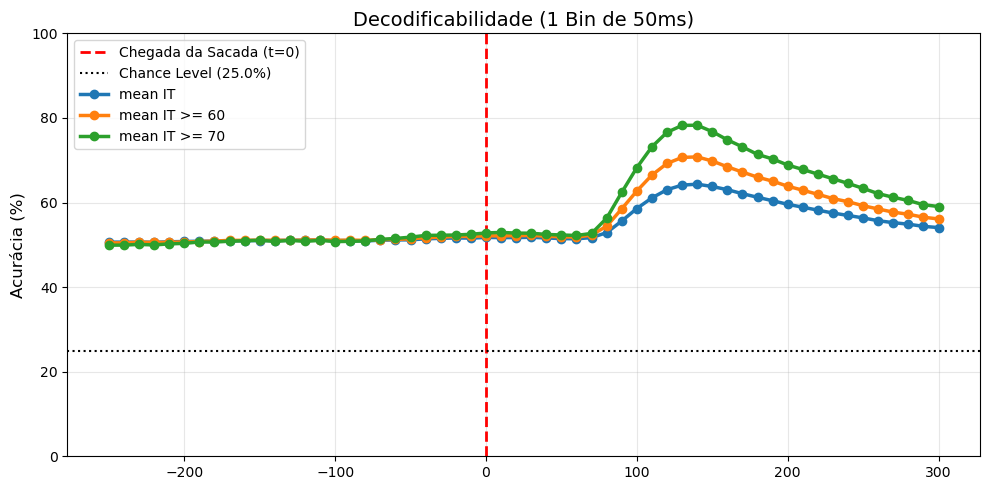

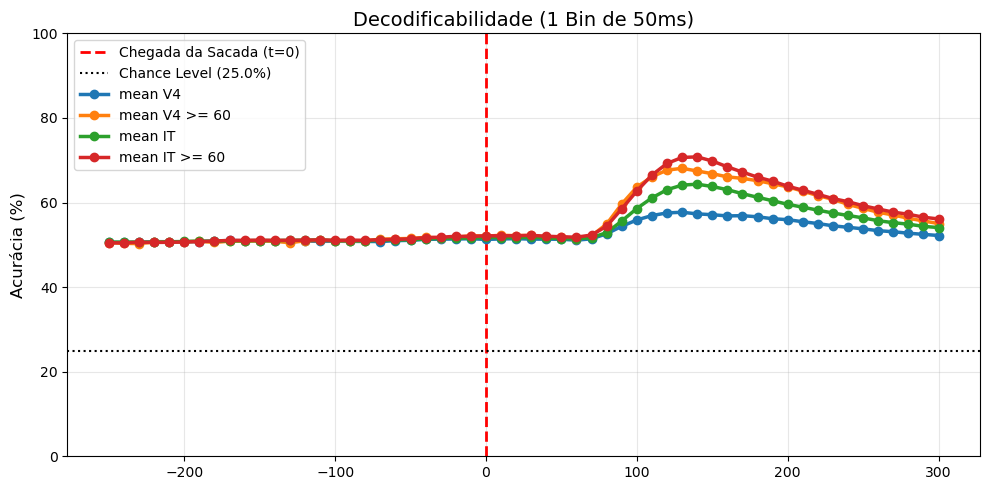

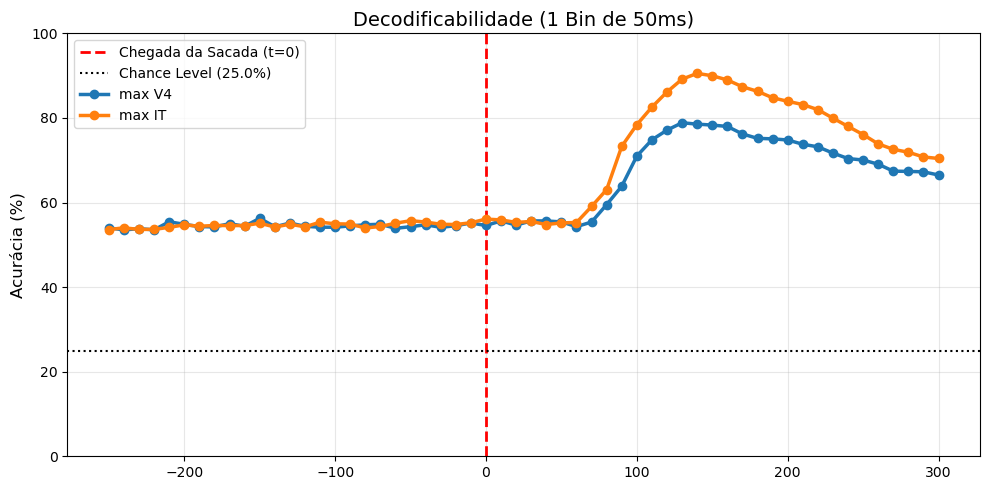

In [75]:
plot_list_decoding(
    [
        np.mean([value['mean_acc'] for value in dicio_acc_V4['restrict'].values()],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_V4['restrict'].values() if value['mean_acc'][37]>=60],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_V4['restrict'].values() if value['mean_acc'][37]>=70],axis=0),
    ],
    [
        'mean V4',
        'mean V4 >= 60',
        'mean V4 >= 70'
    ]
)


plot_list_decoding(
    [
        np.mean([value['mean_acc'] for value in dicio_acc_IT['restrict'].values()],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_IT['restrict'].values() if value['mean_acc'][37]>=60],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_IT['restrict'].values() if value['mean_acc'][37]>=70],axis=0),
    ],
    [
        'mean IT',
        'mean IT >= 60',
        'mean IT >= 70'
    ]
)

plot_list_decoding(
    [
        np.mean([value['mean_acc'] for value in dicio_acc_V4['restrict'].values()],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_V4['restrict'].values() if value['mean_acc'][37]>=60],axis=0),
        # np.mean([value['mean_acc'] for value in dicio_acc_V4['restrict'].values() if value['mean_acc'][37]>=70],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_IT['restrict'].values()],axis=0),
        np.mean([value['mean_acc'] for value in dicio_acc_IT['restrict'].values() if value['mean_acc'][37]>=60],axis=0),
        # np.mean([value['mean_acc'] for value in dicio_acc_IT['restrict'].values() if value['mean_acc'][37]>=70],axis=0),
    ],
    [
        'mean V4',
        'mean V4 >= 60',
        # 'mean V4 >= 70',
        'mean IT',
        'mean IT >= 60',
        # 'mean IT >= 70'
    ]
)



plot_list_decoding(
    [
        np.max([value['mean_acc'] for value in dicio_acc_V4['restrict'].values()],axis=0),
        np.max([value['mean_acc'] for value in dicio_acc_IT['restrict'].values()],axis=0),
    ],
    [
        'max V4',
        'max IT',
    ]
)

In [ ]:
dicio_acc_V4['restrict']['m06cat108']

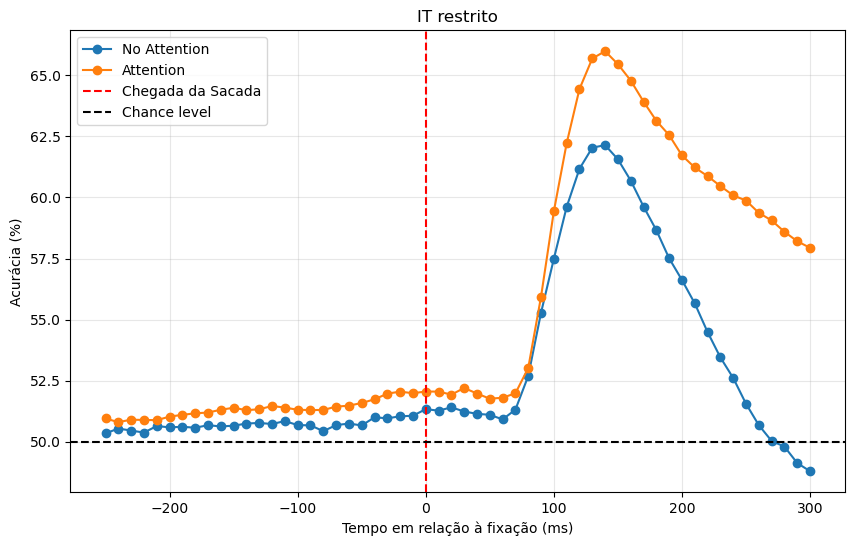

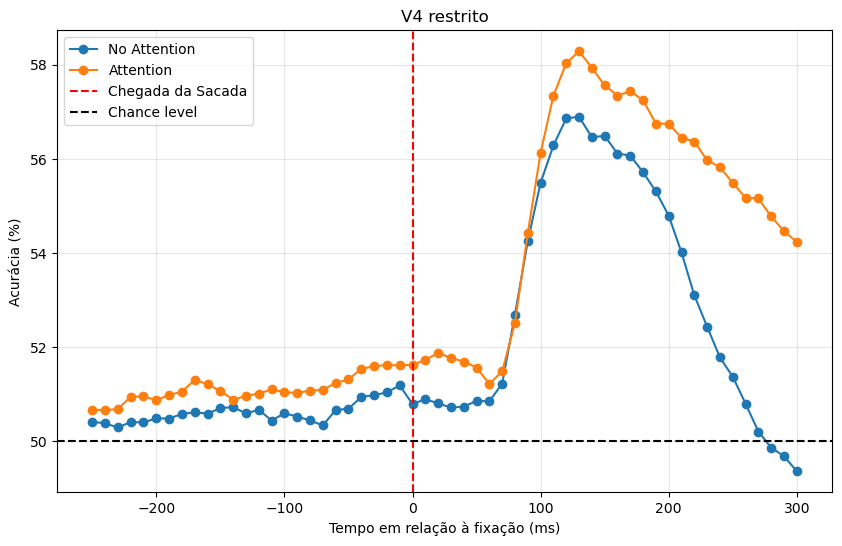

In [ ]:
Classes = dicio_acc_IT['restrict']['m06cat003']['mean_acc_attention'].keys()
dicio_classes = {classe:[] for classe in Classes}
for session, data in dicio_acc_IT['restrict'].items():
        for classe in Classes:
                dicio_classes[classe].append(data['mean_acc_attention'][classe])

dicio_classes_mean = {key: np.mean(value,axis=0) for key,value in dicio_classes.items()}
dicio_classes_mean


plot_decoding_by_class(dicio_classes_mean, Classes, 'IT restrito', chance_level=50)



dicio_classes = {classe:[] for classe in Classes}
for session, data in dicio_acc_V4['restrict'].items():
        for classe in Classes:
                dicio_classes[classe].append(data['mean_acc_attention'][classe])

dicio_classes_mean = {key: np.mean(value,axis=0) for key,value in dicio_classes.items()}
dicio_classes_mean


plot_decoding_by_class(dicio_classes_mean, Classes, 'V4 restrito', chance_level=50)

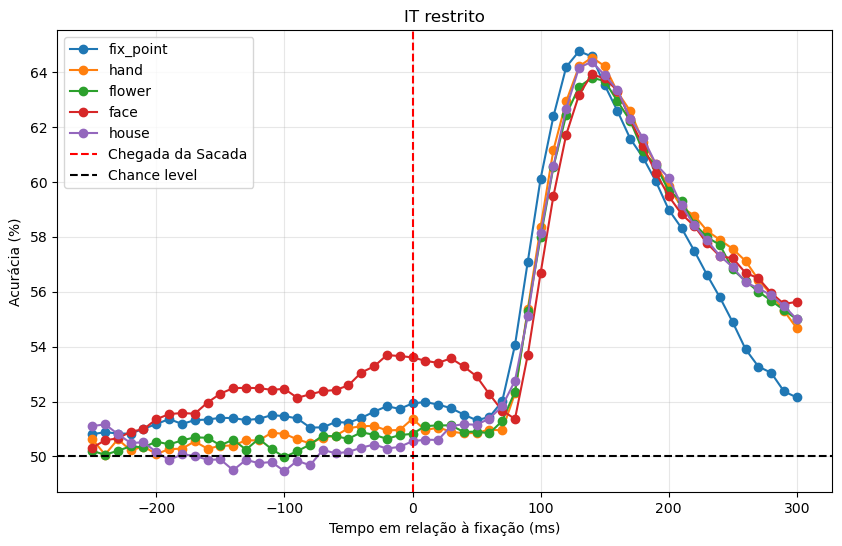

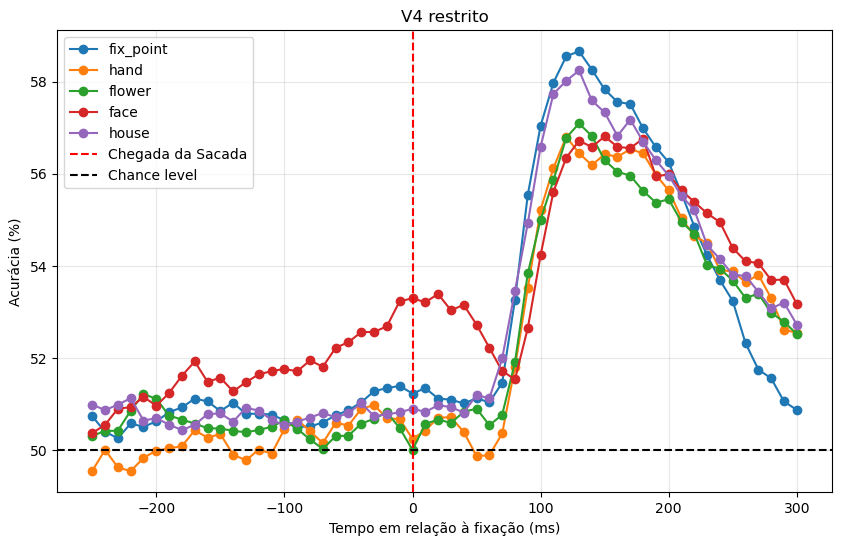

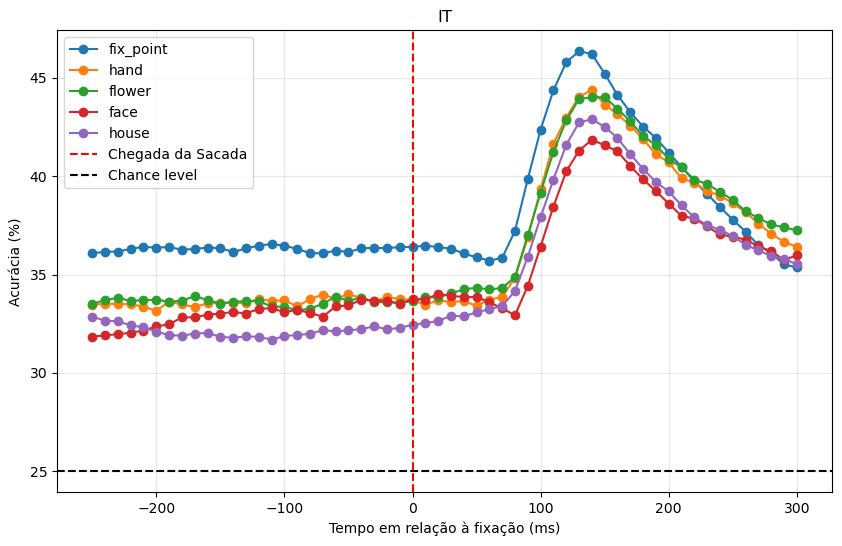

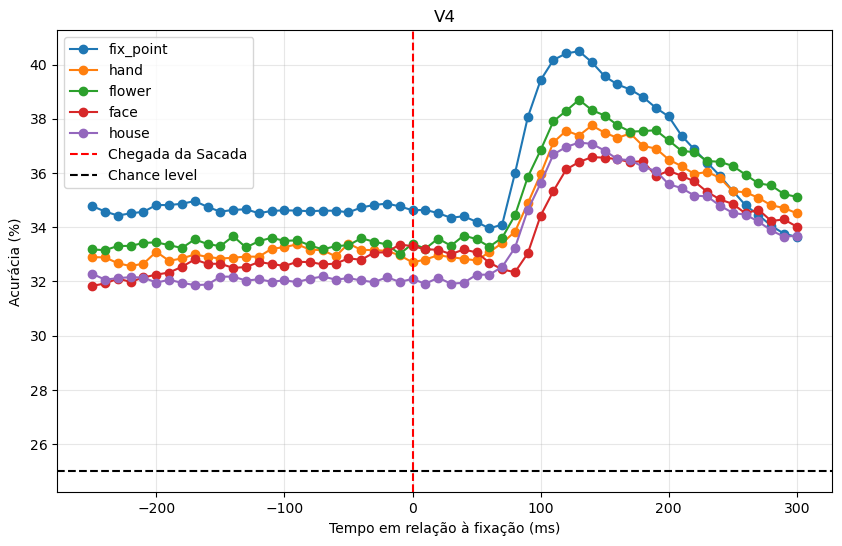

In [89]:
Classes = dicio_acc_IT['restrict']['m06cat003']['mean_acc_cat_anterior'].keys()
dicio_classes = {classe:[] for classe in Classes}
for session, data in dicio_acc_IT['restrict'].items():
        for classe in Classes:
                dicio_classes[classe].append(data['mean_acc_cat_anterior'][classe])

dicio_classes_mean = {key: np.mean(value,axis=0) for key,value in dicio_classes.items()}
dicio_classes_mean


plot_decoding_by_class(dicio_classes_mean, Classes, 'IT restrito', chance_level=50)



dicio_classes = {classe:[] for classe in Classes}
for session, data in dicio_acc_V4['restrict'].items():
        for classe in Classes:
                dicio_classes[classe].append(data['mean_acc_cat_anterior'][classe])

dicio_classes_mean = {key: np.mean(value,axis=0) for key,value in dicio_classes.items()}
dicio_classes_mean


plot_decoding_by_class(dicio_classes_mean, Classes, 'V4 restrito', chance_level=50)


dicio_classes = {classe:[] for classe in Classes}
for session, data in dicio_acc_IT['all'].items():
        for classe in Classes:
                dicio_classes[classe].append(data['mean_acc_cat_anterior'][classe])

dicio_classes_mean = {key: np.mean(value,axis=0) for key,value in dicio_classes.items()}
dicio_classes_mean


plot_decoding_by_class(dicio_classes_mean, Classes, 'IT', chance_level=25)



dicio_classes = {classe:[] for classe in Classes}
for session, data in dicio_acc_V4['all'].items():
        for classe in Classes:
                dicio_classes[classe].append(data['mean_acc_cat_anterior'][classe])

dicio_classes_mean = {key: np.mean(value,axis=0) for key,value in dicio_classes.items()}
dicio_classes_mean


plot_decoding_by_class(dicio_classes_mean, Classes, 'V4', chance_level=25)

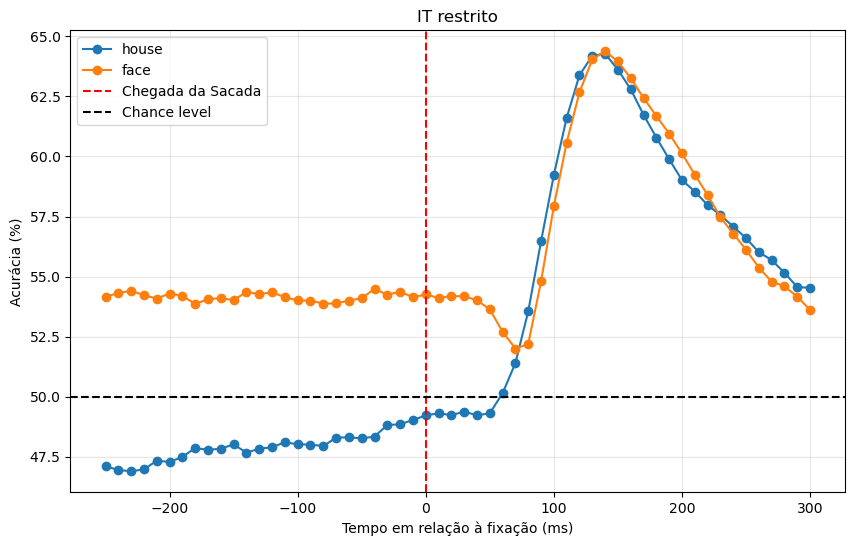

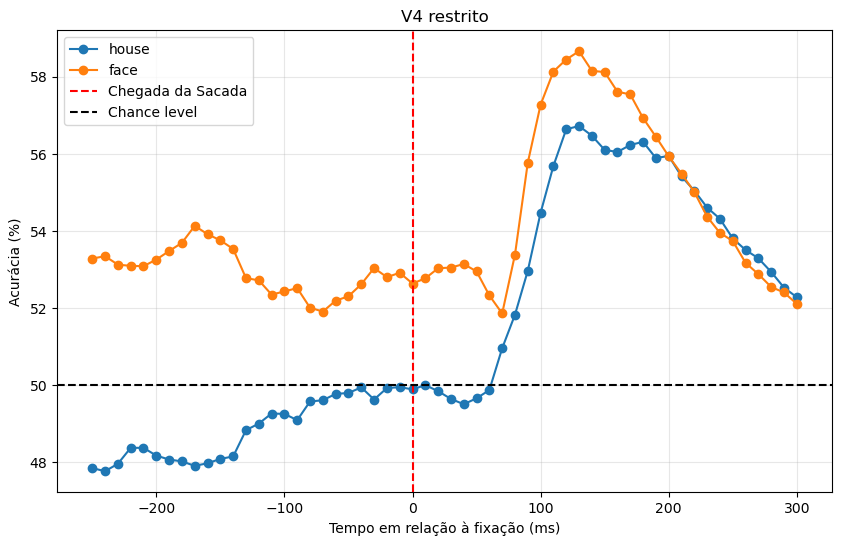

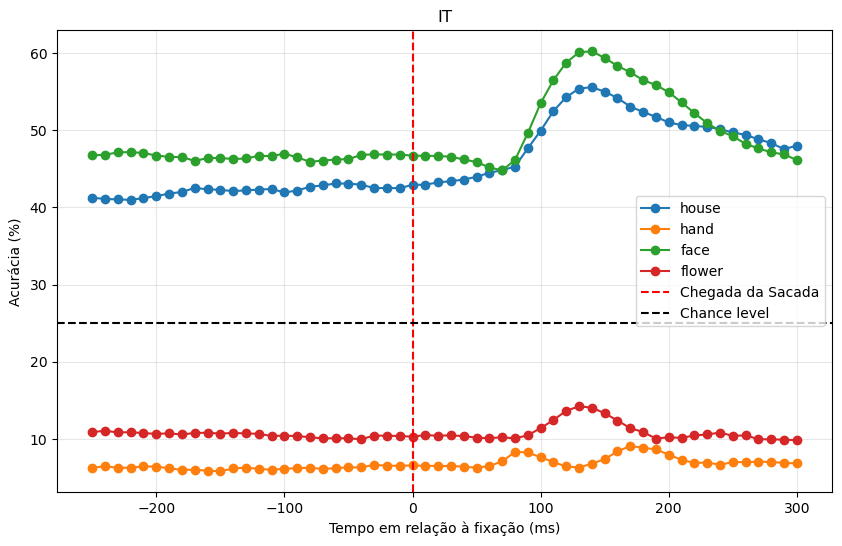

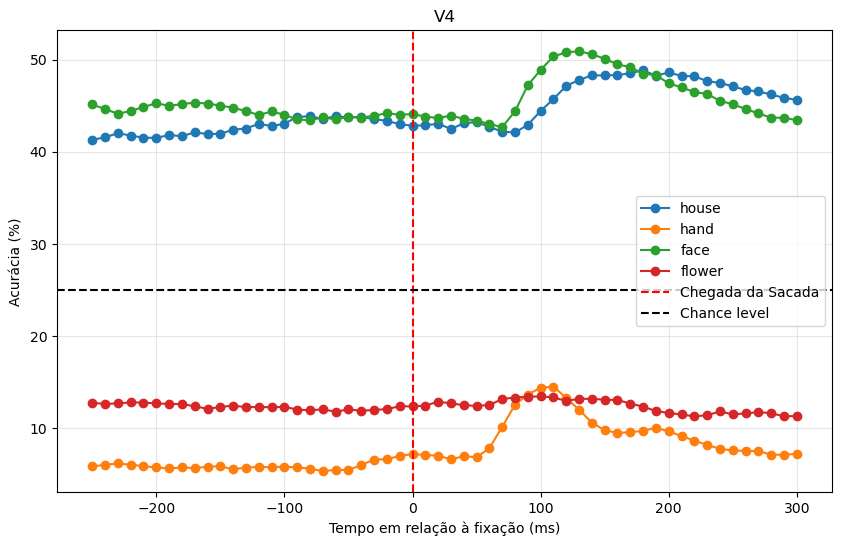

In [92]:
Classes = dicio_acc_IT['restrict']['m06cat003']['mean_acc_cat_atual'].keys()
dicio_classes = {classe:[] for classe in Classes}
for session, data in dicio_acc_IT['restrict'].items():
        for classe in Classes:
                dicio_classes[classe].append(data['mean_acc_cat_atual'][classe])

dicio_classes_mean = {key: np.mean(value,axis=0) for key,value in dicio_classes.items()}
dicio_classes_mean


plot_decoding_by_class(dicio_classes_mean, Classes, 'IT restrito', chance_level=50)



dicio_classes = {classe:[] for classe in Classes}
for session, data in dicio_acc_V4['restrict'].items():
        for classe in Classes:
                dicio_classes[classe].append(data['mean_acc_cat_atual'][classe])

dicio_classes_mean = {key: np.mean(value,axis=0) for key,value in dicio_classes.items()}
dicio_classes_mean


plot_decoding_by_class(dicio_classes_mean, Classes, 'V4 restrito', chance_level=50)


Classes = dicio_acc_IT['all']['m06cat003']['mean_acc_cat_atual'].keys()
dicio_classes = {classe:[] for classe in Classes}
for session, data in dicio_acc_IT['all'].items():
        for classe in Classes:
                dicio_classes[classe].append(data['mean_acc_cat_atual'][classe])

dicio_classes_mean = {key: np.mean(value,axis=0) for key,value in dicio_classes.items()}
dicio_classes_mean


plot_decoding_by_class(dicio_classes_mean, Classes, 'IT', chance_level=25)



dicio_classes = {classe:[] for classe in Classes}
for session, data in dicio_acc_V4['all'].items():
        for classe in Classes:
                dicio_classes[classe].append(data['mean_acc_cat_atual'][classe])

dicio_classes_mean = {key: np.mean(value,axis=0) for key,value in dicio_classes.items()}
dicio_classes_mean


plot_decoding_by_class(dicio_classes_mean, Classes, 'V4', chance_level=25)

# decodificabilidade em t=150 versus numero de neuronios // numero de neuronios seletivos a alguma categoria

In [50]:
df_V4 = {}
df_IT = {}
for session, numero in dicio_Nneurons_V4.items():
    df_V4[session] = [numero, dicio_Nselective_V4[session], dicio_acc_V4['all'][session]['mean_acc'][40]]
for session, numero in dicio_Nneurons_IT.items():
    df_IT[session] = [numero, dicio_Nselective_IT[session], dicio_acc_IT['all'][session]['mean_acc'][40]]

In [65]:
# pd.DataFrame(df_IT, index=['n_neurons','n_selective','acc']).T.sort_values('acc').head(50)
# pd.DataFrame(df_IT, index=['n_neurons','n_selective','acc']).T.sort_values('acc').tail(50)

### testar numero, e vai dar bom. como testar se seletividade tem efeito Independente Do Numero?

manifold neural de cada categoria?

# atividade versus decodificabilidade

In [ ]:
# isso eu teria que fazer dentro do run decorder, splittando entre trials de atividade alta x baixa x media talvez. ou outra divisao CATEGORICA, e nao continua (talvez seria possivel, tem q pesquisar)

# atividade versus atenção

In [ ]:
# zscores de (rosto, casa) alvo são maiores que (rosto, casa) não alvo?


# Passo 1 (O Z-Score Global): Você calcula a média ($\mu$) e o desvio padrão ($\sigma$) de cada neurônio usando todos os eventos válidos da tarefa (ou todos os eventos de busca, exatamente como no primeiro exemplo).
# Passo 2 (A Aplicação): Você aplica esse mesmo $z$-score a todas as sacadas.
# Passo 3 (O Filtro/Split posterior): Só depois de o $z$-score estar calculado de forma global é que você usa o metadado para fatiar os dados: 
# "Agora, peguem apenas as sacadas de rostos e casas, separem quais eram a pista (alvo) e quais eram distratores, e comparem os valores de $z$-score entre os dois grupos".;

## para checar se nunca tem sinal pre sacadico (t=0) ver se os que tem maxima decodificabilidade em t=0 tem matriz de difusao com diagonais marcadas

## pq a media de decodificabilidade por alvo atual deu 33%;;;;
 PQ TA TUDO ERRADO 

- [ ]  faz sentido fazer a média Por Sessao das acuracias médias?
- [ ]  Seletividade x Decoding
- [ ]  Numero de neuronios x Decoding
- ver sobre Atividade, oq vou medir — já medir em 1 sessao e ver oq vou medir e guardar nas outras**
- [ ]  Resposta [atividade, mais disparo] (pré ou pos sacc) x Decoding (pos-sacc)
- [ ]  Resposta [atividade, mais disparo] x é alvo
